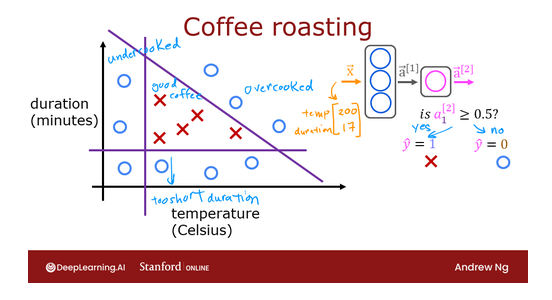

In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split
import kagglehub
from pathlib import Path

In [19]:
coffee_roasting_df = pd.read_csv("coffee_roasting.csv")

In [20]:
coffee_roasting_df.head()

,Temprature,Duration,Target
0,185.32,12.69,1
1,259.92,11.87,0
2,231.01,14.41,0
3,175.37,11.72,0
4,187.12,14.13,1


In [21]:
coffee_roasting_df["Temperature"] = coffee_roasting_df["Temprature"] # Adjusting the column name

In [22]:
coffee_roasting_df.head()

,Temprature,Duration,Target,Temperature
0,185.32,12.69,1,185.32
1,259.92,11.87,0,259.92
2,231.01,14.41,0,231.01
3,175.37,11.72,0,175.37
4,187.12,14.13,1,187.12


In [25]:
coffee_roasting_df = coffee_roasting_df.drop("Temprature", axis=1)

In [59]:
coffee_roasting_df.head() # Now its right

,Duration,Target,Temperature
0,12.69,1,185.32
1,11.87,0,259.92
2,14.41,0,231.01
3,11.72,0,175.37
4,14.13,1,187.12


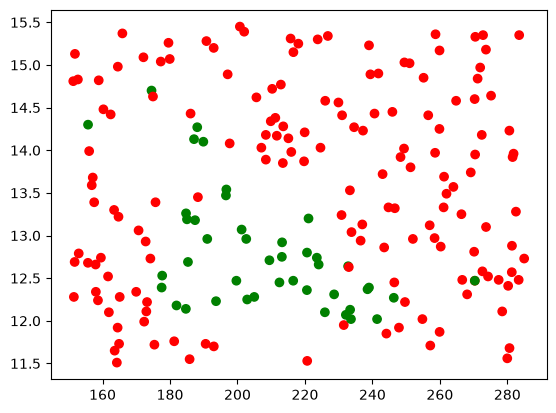

In [66]:
plt.scatter(coffee_roasting_df["Temperature"], coffee_roasting_df["Duration"], c=coffee_roasting_df["Target"].map({0: "red", 1: "green"}))
plt.show()

In [106]:
coffee_roasting_df_train, coffee_roasting_df_test = train_test_split(coffee_roasting_df, test_size=0.2, random_state=42)

In [107]:
X = coffee_roasting_df_train[["Temperature", "Duration"]].to_numpy(dtype=np.float32)

In [111]:
norm_l = tf.keras.layers.Normalization()
norm_l.adapt(X)
Xn = norm_l(X)

In [112]:
normalized_coffee_roast_df_train = pd.DataFrame(Xn, columns=["Temperature", "Duration"])

In [113]:
normalized_coffee_roast_df_train.head() # Now our data is normalized

,Temperature,Duration
0,0.414589,0.687734
1,1.394815,-0.346352
2,1.559230,-0.956198
3,-1.364404,-1.627913
4,-0.964394,1.562731


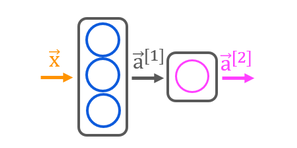

In [102]:
# Defining the coffee roast model
model = Sequential([
    tf.keras.Input(shape=(2,)), # Enables the model to instantiate the parameters without needed to call 'model.fit()'
    Dense(3, activation="sigmoid", name="layer1"),
    Dense(1, activation="sigmoid", name="layer2")
])

In [103]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 3)              │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13 (52.00 B)

 Trainable params: 13 (52.00 B)

 Non-trainable params: 0 (0.00 B)

In [98]:
W1, b1 = model.get_layer("layer1").get_weights()
W2, b2 = model.get_layer("layer2").get_weights()

In [99]:
print(f"W1{W1.shape}:\n", W1, f"\nb1{b1.shape}:", b1)
print(f"W2{W2.shape}:\n", W2, f"\nb2{b2.shape}:", b2)

W1(2, 3):
 [[ 0.53895235 -0.24340206 -0.78112113]
 [ 0.2843231   0.32303703 -0.9681929 ]] 
b1(3,): [0. 0. 0.]
W2(3, 1):
 [[-0.36442804]
 [-0.05364513]
 [-0.9925628 ]] 
b2(1,): [0.]


In [124]:
model.compile(loss=tf.keras.losses.BinaryCrossentropy(), optimizer=tf.keras.optimizers.Adam(learning_rate=0.01))

In [128]:
model.fit(normalized_coffee_roast_df_train.to_numpy(dtype=np.float32), coffee_roasting_df_train["Target"], epochs=10)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1956 
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1956 
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1956 
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1956 
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1956 
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1956 
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1956 
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1956 
Epoch 9/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1956 
Epoch 10/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1956 


In [129]:
# After fitting, the parameters may have been updated
W1, b1 = model.get_layer("layer1").get_weights()
W2, b2 = model.get_layer("layer2").get_weights()

In [130]:
print(f"W1{W1.shape}:\n", W1, f"\nb1{b1.shape}:", b1)
print(f"W2{W2.shape}:\n", W2, f"\nb2{b2.shape}:", b2)

W1(2, 3):
 [[ 3.9312394 10.76303   -4.3734984]
 [ 6.0888176  5.1376653 -1.2671833]] 
b1(3,): [-2.088068  -0.3977552 -6.2160573]
W2(3, 1):
 [[-6.327698 ]
 [-4.9104395]
 [-9.943598 ]] 
b2(1,): [2.3913713]


In [131]:
X_test = np.array([
    [200,13.9],
    [200,17]
])
X_test_normalized = norm_l(X_test)

In [132]:
predictions = model.predict(X_test_normalized)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


In [133]:
print("predictions = \n", predictions)

predictions = 
 [[7.5767845e-01]
 [1.4343769e-04]]


In [138]:
yhat = (predictions >= 0.5).astype(int)

In [141]:
print(f"decisions = \n{yhat}")

decisions = 
[[1]
 [0]]
